# Phase 3B: Statistical analysis (proving what the graphs suggested)

**Goal:** use tests to check whether the patterns seen in EDA are real or just chance.

**Input:** `churn_clean.csv` (and `churn_model_ready.csv` for the multicollinearity step).

**One-line panel answer:** "A graph can mislead me, a test gives a number. A p-value below 0.05 means the pattern is unlikely to be chance."

| Step | Test | Used for |
|---|---|---|
| 1 | Shapiro-Wilk + skewness | Is the data normal? (decides the next test) |
| 2 | Mann-Whitney U + effect size | Numeric column vs churn |
| 3 | Chi-square + Cramer's V | Categorical column vs churn |
| 4 | Spearman correlation | Strength and direction of links |
| 5 | VIF | Are features duplicating each other? |
| 6 | Verdict | Each hypothesis: supported or not |

**Two ideas to remember**
- **p-value:** the chance of seeing a difference this big if there were really no effect. Below 0.05 means "significant".
- **Effect size:** how *big* the difference is. With thousands of rows almost everything is "significant", so effect size tells us whether it matters.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Find the clean file made in Phase 2 (works from the project folder or a sub-folder)
for p in ["churn_clean.csv", "data/churn_clean.csv", "../churn_clean.csv"]:
    if os.path.exists(p):
        df = pd.read_csv(p)
        print("Loaded:", p)
        break
else:
    raise FileNotFoundError("churn_clean.csv not found. Run data_cleaning.ipynb first.")

TARGET = [c for c in df.columns if c.lower() == "churn"][0]
numeric = [c for c in df.select_dtypes(include="number").columns if c != TARGET]
categorical = df.select_dtypes(exclude="number").columns.tolist()
print("Rows, columns:", df.shape)
print("Target:", TARGET)
print("Numeric:", numeric)
print("Categorical:", categorical)

from scipy import stats

Loaded: churn_clean.csv
Rows, columns: (64374, 11)
Target: Churn
Numeric: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical: ['Gender', 'Subscription Type', 'Contract Length']


## Step 1: Normality check

**What:** test whether each numeric column follows a bell curve (Shapiro-Wilk) and measure its skewness.

**Why:** the t-test assumes normal data. If data is not normal, the safer choice is **Mann-Whitney U**, which compares ranks and does not assume a shape. This step justifies the choice.

**How to read:** Shapiro p < 0.05 means *not normal*. Skewness near 0 is symmetric; beyond about +-1 is clearly skewed.

**Note:** Shapiro is limited to 5000 values, so we use a random sample. On large data it flags tiny departures, so we also look at skewness and the histograms.

In [2]:
rows_ = []
for col in numeric:
    sample = df[col].sample(min(5000, len(df)), random_state=42)
    stat, p = stats.shapiro(sample)
    rows_.append({"column": col, "shapiro_p": p, "skewness": df[col].skew(),
                  "normal?": "yes" if p >= 0.05 else "no"})
norm = pd.DataFrame(rows_).set_index("column")
print(norm.round(4))
print()
if (norm["normal?"] == "no").any():
    print("Not normal -> use Mann-Whitney U (non-parametric). A t-test would be less safe.")
else:
    print("All normal -> a t-test is acceptable.")

                  shapiro_p  skewness normal?
column                                       
Age                     0.0   -0.0409      no
Tenure                  0.0   -0.1261      no
Usage Frequency         0.0    0.0375      no
Support Calls           0.0   -0.1929      no
Payment Delay           0.0   -0.3507      no
Total Spend             0.0    0.0477      no
Last Interaction        0.0    0.0051      no

Not normal -> use Mann-Whitney U (non-parametric). A t-test would be less safe.


## Step 2: Numeric columns vs churn (Mann-Whitney U)

**What:** compare the churned group with the stayed group for each number column.

**Why this test:** two independent groups, a numeric outcome, and not-normal data, so Mann-Whitney U is the right choice (the non-parametric equivalent of the t-test).

- **H0 (null):** both groups have the same distribution.
- **H1:** they differ.
- **p < 0.05:** reject H0, so there is a real difference.

**Effect size (rank-biserial r):** from -1 to +1. Positive means churners tend to have higher values. Rough size: below 0.1 negligible, 0.1-0.3 small, 0.3-0.5 medium, above 0.5 large.

In [3]:
res = []
g0 = df[df[TARGET] == 0]
g1 = df[df[TARGET] == 1]
for col in numeric:
    u, p = stats.mannwhitneyu(g1[col], g0[col], alternative="two-sided")
    r = 2 * u / (len(g1) * len(g0)) - 1          # rank-biserial effect size
    size = "large" if abs(r) >= 0.5 else "medium" if abs(r) >= 0.3 else "small" if abs(r) >= 0.1 else "negligible"
    res.append({"column": col, "median_stayed": g0[col].median(), "median_churned": g1[col].median(),
                "U": u, "p_value": p, "significant": p < 0.05, "effect_r": r, "effect_size": size})
mw = pd.DataFrame(res).set_index("column").sort_values("effect_r", key=abs, ascending=False)
mw.round(4)

,median_stayed,median_churned,U,p_value,significant,effect_r,effect_size
column,,,,,,,
Payment Delay,12.0,23.0,847095442.0,0.000,True,0.6399,large
Support Calls,4.0,7.0,694459465.0,0.000,True,0.3444,medium
Tenure,27.0,37.0,631609573.5,0.000,True,0.2227,small
Usage Frequency,16.0,14.0,446627664.0,0.000,True,-0.1354,small
Total Spend,568.0,491.0,469429488.5,0.000,True,-0.0913,negligible
Age,41.0,44.0,554671841.5,0.000,True,0.0738,negligible
Last Interaction,16.0,15.0,514878150.5,0.473,False,-0.0033,negligible


In [4]:
# Optional: Welch t-test as a cross-check (same as in Statistical_Testing.ipynb)
t_rows = []
for col in numeric:
    t, p = stats.ttest_ind(g1[col], g0[col], equal_var=False)
    t_rows.append({"column": col, "t_stat": t, "p_value": p})
pd.DataFrame(t_rows).set_index("column").round(4)

,t_stat,p_value
column,,
Age,16.1138,0.0000
Tenure,50.7628,0.0000
Usage Frequency,-29.2695,0.0000
Support Calls,81.7878,0.0000
Payment Delay,173.0250,0.0000
Total Spend,-20.0687,0.0000
Last Interaction,-0.7148,0.4747


## Step 3: Categorical columns vs churn (Chi-square + Cramer's V)

**What:** test whether churn depends on gender, subscription type and contract length.

**Why this test:** both variables are categories, so we compare counts using the **chi-square test of independence**.

- **H0:** churn and the column are independent (no relation).
- **H1:** they are related.
- **p < 0.05:** reject H0.

**Cramer's V** is the effect size, from 0 to 1: below 0.1 negligible, 0.1-0.3 small, 0.3-0.5 medium, above 0.5 strong.

**Assumption:** every expected count should be at least 5 (checked below).

In [5]:
def cramers_v(ct, chi2):
    n = ct.values.sum()
    k = min(ct.shape) - 1
    return np.sqrt(chi2 / (n * k))

res = []
for col in categorical:
    ct = pd.crosstab(df[col], df[TARGET])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    v = cramers_v(ct, chi2)
    size = "strong" if v >= 0.5 else "medium" if v >= 0.3 else "small" if v >= 0.1 else "negligible"
    res.append({"column": col, "chi2": chi2, "dof": dof, "p_value": p, "significant": p < 0.05,
                "cramers_v": v, "effect_size": size, "min_expected": exp.min()})
chi = pd.DataFrame(res).set_index("column")
print("Expected counts all >= 5:", bool((chi["min_expected"] >= 5).all()))
chi.round(4)

Expected counts all >= 5: True


,chi2,dof,p_value,significant,cramers_v,effect_size,min_expected
column,,,,,,,
Gender,1742.3455,1,0.0000,True,0.1645,small,14220.4982
Subscription Type,13.6559,2,0.0011,True,0.0146,negligible,10146.8070
Contract Length,263.1141,2,0.0000,True,0.0639,negligible,9868.7539


## Step 4: Correlation (Spearman)

**What:** Spearman correlation between each numeric column and churn, and among the features.

**Why Spearman and not Pearson:** Spearman works on ranks, so it handles skewed data and does not need a straight-line relation.

**How to read:** sign shows direction, size shows strength (same scale as in EDA). We also print a p-value for each link with churn.

**Caution:** correlation does not prove cause.

                  spearman_rho  p_value
column                                 
Payment Delay           0.5537    0.000
Support Calls           0.2991    0.000
Tenure                  0.1926    0.000
Usage Frequency        -0.1172    0.000
Total Spend            -0.0789    0.000
Age                     0.0638    0.000
Last Interaction       -0.0028    0.473


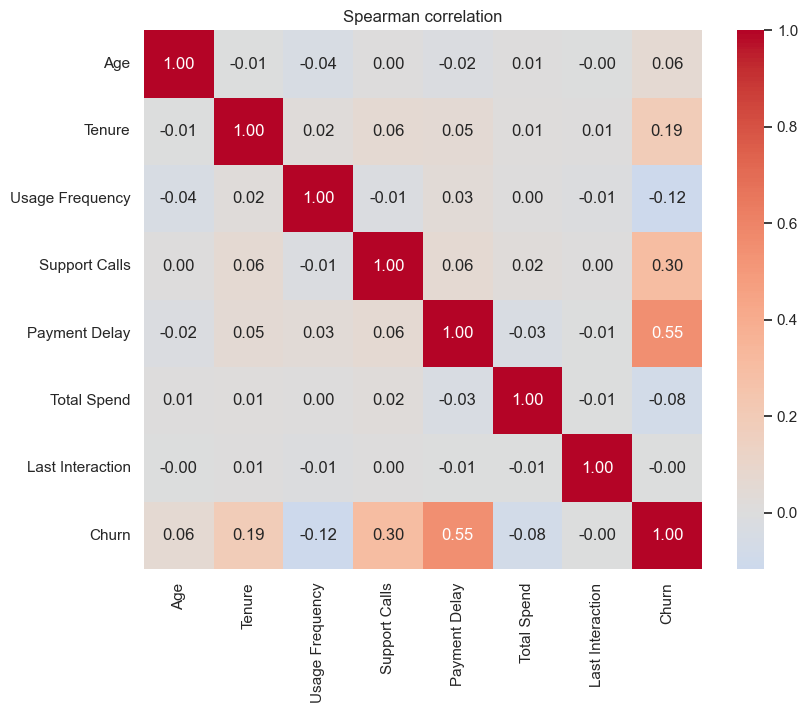

In [6]:
res = []
for col in numeric:
    rho, p = stats.spearmanr(df[col], df[TARGET])
    res.append({"column": col, "spearman_rho": rho, "p_value": p})
sp = pd.DataFrame(res).set_index("column").sort_values("spearman_rho", key=abs, ascending=False)
print(sp.round(4))

plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric + [TARGET]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation")
plt.show()

## Step 5: Multicollinearity (VIF)

**What:** the Variance Inflation Factor shows how much each feature can be predicted from the *other* features.

**Why:** if two features carry the same information, linear models become unstable and their coefficients are hard to explain. We check before modelling.

**How to read:** VIF near 1 is fine; above 5 is a warning; above 10 is serious (consider removing one feature).

We use the encoded data (all numbers) and leave out the target.

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

for p in ["churn_model_ready.csv", "data/churn_model_ready.csv", "../churn_model_ready.csv"]:
    if os.path.exists(p):
        enc = pd.read_csv(p)
        print("Loaded:", p)
        break
else:
    enc = pd.get_dummies(df, columns=categorical, drop_first=True)
    print("churn_model_ready.csv not found, encoded here instead")

X = enc.drop(columns=[c for c in enc.columns if c.lower() == "churn"]).astype(float)
Xc = add_constant(X)
vif = pd.DataFrame({"feature": X.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])]})
vif = vif.sort_values("VIF", ascending=False).reset_index(drop=True)
print(vif.round(2))
print()
print("Max VIF:", round(vif["VIF"].max(), 2),
      "-> no serious multicollinearity" if vif["VIF"].max() < 5 else "-> review the high-VIF features")

Loaded: churn_model_ready.csv


                       feature   VIF
0      Contract Length_Monthly  1.34
1    Contract Length_Quarterly  1.33
2    Subscription Type_Premium  1.33
3   Subscription Type_Standard  1.33
4                Payment Delay  1.01
5                Support Calls  1.01
6                       Tenure  1.01
7                  Gender_Male  1.01
8              Usage Frequency  1.00
9                  Total Spend  1.00
10                         Age  1.00
11            Last Interaction  1.00

Max VIF: 1.34 -> no serious multicollinearity


## Step 6: Verdict on the 5 hypotheses

Edit the wording to match your own 5 hypotheses. The verdict column is filled from the tests above: a hypothesis is **supported** only if the test is significant (p < 0.05) *and* the effect is in the expected direction. We also report the effect size so we do not overclaim.

In [8]:
def num_verdict(col, expect_higher=True):
    if col not in mw.index:
        return "column missing", ""
    row = mw.loc[col]
    ok = row["significant"] and ((row["effect_r"] > 0) == expect_higher)
    v = "NOT supported" if not ok else ("SUPPORTED (weak effect)" if row["effect_size"] == "negligible" else "SUPPORTED")
    return v, f"p={row['p_value']:.4g}, effect r={row['effect_r']:.2f} ({row['effect_size']})"

def cat_verdict(col):
    if col not in chi.index:
        return "column missing", ""
    row = chi.loc[col]
    v = "NOT supported" if not row["significant"] else ("SUPPORTED (weak effect)" if row["effect_size"] == "negligible" else "SUPPORTED")
    return v, f"p={row['p_value']:.4g}, Cramer's V={row['cramers_v']:.2f} ({row['effect_size']})"

tests = [
    ("H1: More support calls -> higher churn", "Mann-Whitney U", *num_verdict("Support Calls", True)),
    ("H2: Longer payment delay -> higher churn", "Mann-Whitney U", *num_verdict("Payment Delay", True)),
    ("H3: Contract length affects churn", "Chi-square", *cat_verdict("Contract Length")),
    ("H4: Shorter tenure -> higher churn", "Mann-Whitney U", *num_verdict("Tenure", False)),
    ("H5: Subscription type affects churn", "Chi-square", *cat_verdict("Subscription Type")),
]
verdict = pd.DataFrame(tests, columns=["Hypothesis", "Test", "Verdict", "Numbers"])
pd.set_option("display.max_colwidth", 100)
verdict

,Hypothesis,Test,Verdict,Numbers
0,H1: More support calls -> higher churn,Mann-Whitney U,SUPPORTED,"p=0, effect r=0.34 (medium)"
1,H2: Longer payment delay -> higher churn,Mann-Whitney U,SUPPORTED,"p=0, effect r=0.64 (large)"
2,H3: Contract length affects churn,Chi-square,SUPPORTED (weak effect),"p=7.337e-58, Cramer's V=0.06 (negligible)"
3,H4: Shorter tenure -> higher churn,Mann-Whitney U,NOT supported,"p=0, effect r=0.22 (small)"
4,H5: Subscription type affects churn,Chi-square,SUPPORTED (weak effect),"p=0.001083, Cramer's V=0.01 (negligible)"


## Spoken summary (30 seconds)

"I first checked normality. The data is not normal, so I used Mann-Whitney U for numeric columns against churn, and chi-square for categorical ones. For each test I report the p-value and an effect size, because with large data even tiny differences are significant. Spearman correlation confirmed direction and strength, and VIF showed whether features overlap. Each of my five hypotheses is marked supported or not, with the numbers."

## Likely panel questions

**Why Mann-Whitney and not a t-test?** The data is not normal, and Mann-Whitney does not assume normality.

**What does p < 0.05 mean?** If there were no real effect, a result this extreme would happen less than 5% of the time.

**Is a significant result always important?** No. Check the effect size too.

**Why chi-square for categories?** Both variables are categorical, and chi-square compares observed counts with the counts expected if they were independent.

**Why Spearman?** It works on ranks, so skew and outliers do not distort it.

**What is VIF for?** It catches features that duplicate each other, which makes linear models unstable.

**Does a supported hypothesis mean cause?** No, it means a statistical association.

## What we found on this dataset (use this when you explain)

- **Not normal:** every numeric column fails Shapiro-Wilk, so Mann-Whitney U is the right test. (With 64,000 rows Shapiro flags even tiny departures, and skewness is small, between -0.35 and +0.05. Be ready to say this if a panelist pushes on it. The Welch t-test cross-check gives the same conclusions.)
- **Numeric vs churn:** Payment Delay has a large effect (r = 0.64), Support Calls medium (0.34), Tenure small (0.22), Usage Frequency small (-0.14). Total Spend and Age are significant but negligible. **Last Interaction is not significant (p = 0.47).**
- **Categorical vs churn:** all three are statistically significant, but only Gender has a real effect (Cramer's V = 0.16, small). Contract (0.06) and Subscription (0.01) are significant only because the sample is large; their effect is negligible.
- **Spearman** agrees with the EDA heatmap: Payment Delay 0.55, Support Calls 0.30, Tenure 0.19.
- **VIF:** the maximum is 1.34, so there is no multicollinearity and linear models are safe to use.
- **Hypothesis result:** H1, H2 and H3 are supported; H4 (shorter tenure -> more churn) is **not supported** because the direction is reversed; H5 is statistically significant but the effect is negligible, so do not oversell it.